# STEP 2 - Coarse Overview

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']


# View 1

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


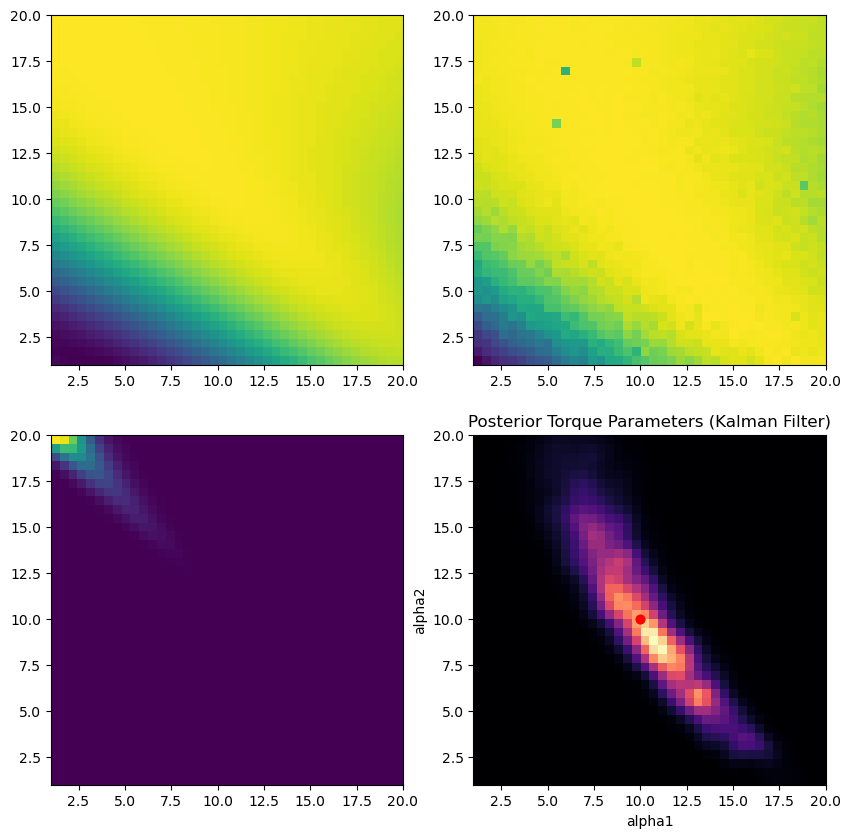

In [2]:
alpha1_min = 0.1 * ALPHA1
alpha1_max = 2 * ALPHA1
alpha2_min = 0.1 * ALPHA2
alpha2_max = 2 * ALPHA2


resolution = 40

alpha1_grid = np.linspace(alpha1_min, alpha1_max, resolution)
alpha2_grid = np.linspace(alpha2_min, alpha2_max, resolution)

ALPHA1_GRID, ALPHA2_GRID = np.meshgrid(alpha1_grid, alpha2_grid)
shape_chunk = ALPHA1_GRID.shape
ALPHA1_GRID = ALPHA1_GRID.flatten()
ALPHA2_GRID = ALPHA2_GRID.flatten()

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

params = np.stack((ALPHA1_GRID, ALPHA2_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][0].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][0].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman1.png', dpi=300)

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

particle_P_gamma = 10
cmap = 'viridis' if particle_P_gamma == 1 else 'magma'
P = np.exp((logl - np.max(logl))/particle_P_gamma)
P /= np.sum(P)
P = gaussian_filter(P, 1)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][1].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][1].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto', cmap=cmap)
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
ax[1][1].plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.savefig('particle1.png', dpi=300)
plt.show()

# View 2

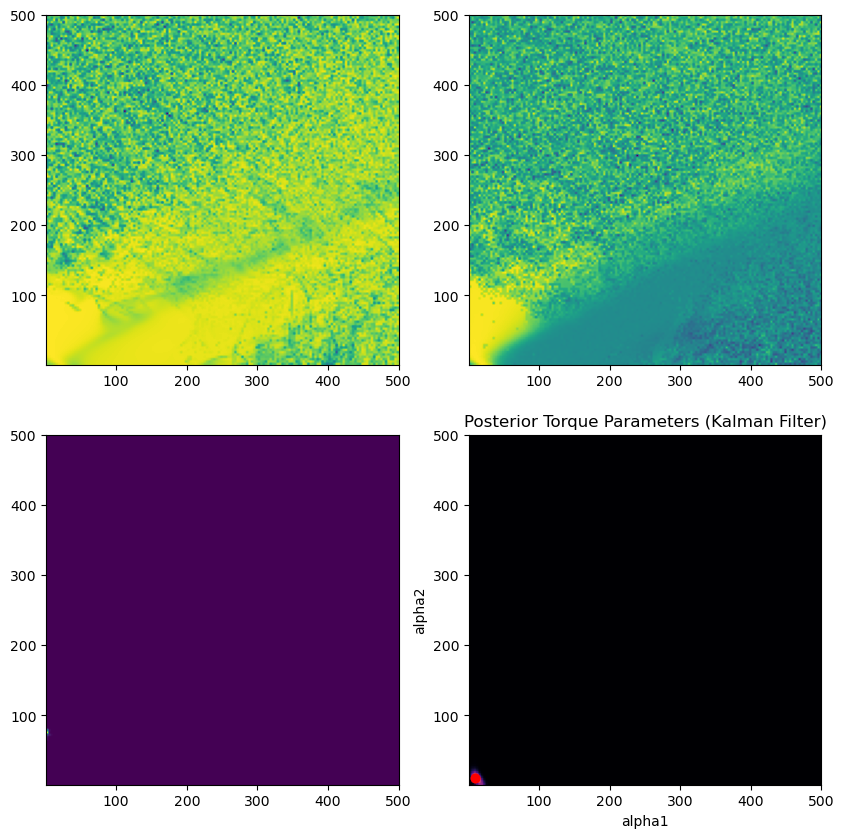

In [3]:
alpha1_min = 0.1 * ALPHA1
alpha1_max = 50 * ALPHA1
alpha2_min = 0.1 * ALPHA2
alpha2_max = 50 * ALPHA2


resolution = 150

alpha1_grid = np.linspace(alpha1_min, alpha1_max, resolution)
alpha2_grid = np.linspace(alpha2_min, alpha2_max, resolution)

ALPHA1_GRID, ALPHA2_GRID = np.meshgrid(alpha1_grid, alpha2_grid)
shape_chunk = ALPHA1_GRID.shape
ALPHA1_GRID = ALPHA1_GRID.flatten()
ALPHA2_GRID = ALPHA2_GRID.flatten()

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

params = np.stack((ALPHA1_GRID, ALPHA2_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][0].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][0].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman1.png', dpi=300)

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

particle_P_gamma = 10
cmap = 'viridis' if particle_P_gamma == 1 else 'magma'
P = np.exp((logl - np.max(logl))/particle_P_gamma)
P /= np.sum(P)
P = gaussian_filter(P, 1)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][1].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][1].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto', cmap=cmap)
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
ax[1][1].plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.savefig('particle1.png', dpi=300)
plt.show()

# View 3

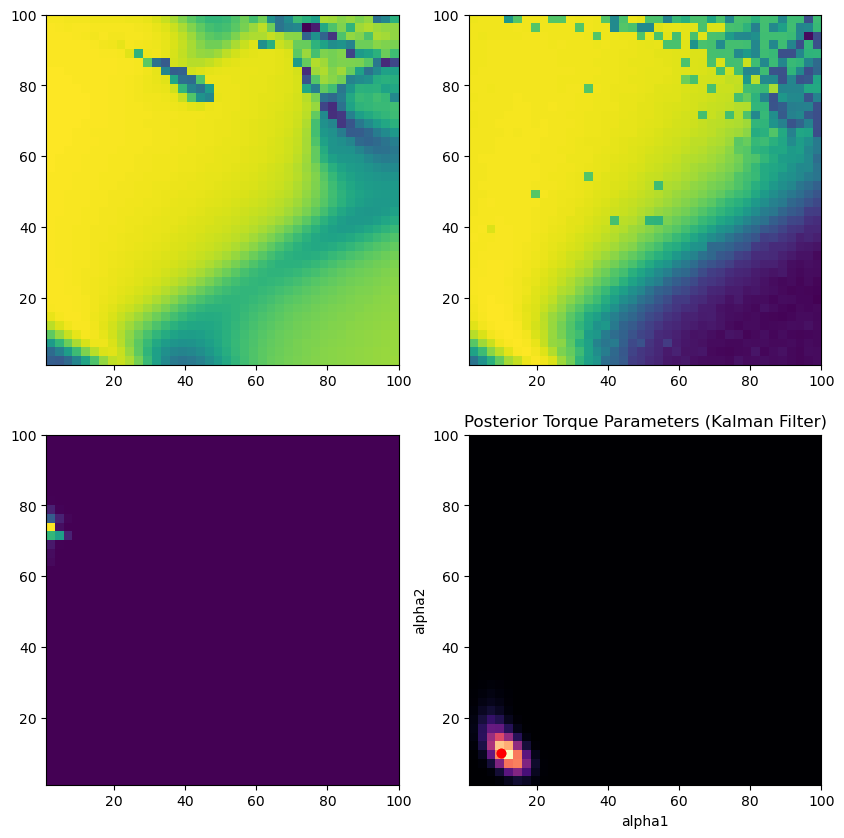

In [4]:
alpha1_min = 0.1 * ALPHA1
alpha1_max = 10 * ALPHA1
alpha2_min = 0.1 * ALPHA2
alpha2_max = 10 * ALPHA2


resolution = 40

alpha1_grid = np.linspace(alpha1_min, alpha1_max, resolution)
alpha2_grid = np.linspace(alpha2_min, alpha2_max, resolution)

ALPHA1_GRID, ALPHA2_GRID = np.meshgrid(alpha1_grid, alpha2_grid)
shape_chunk = ALPHA1_GRID.shape
ALPHA1_GRID = ALPHA1_GRID.flatten()
ALPHA2_GRID = ALPHA2_GRID.flatten()

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

params = np.stack((ALPHA1_GRID, ALPHA2_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][0].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][0].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman1.png', dpi=300)

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

particle_P_gamma = 10
cmap = 'viridis' if particle_P_gamma == 1 else 'magma'
P = np.exp((logl - np.max(logl))/particle_P_gamma)
P /= np.sum(P)
P = gaussian_filter(P, 1)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][1].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][1].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto', cmap=cmap)
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
ax[1][1].plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.savefig('particle1.png', dpi=300)
plt.show()

# View 5

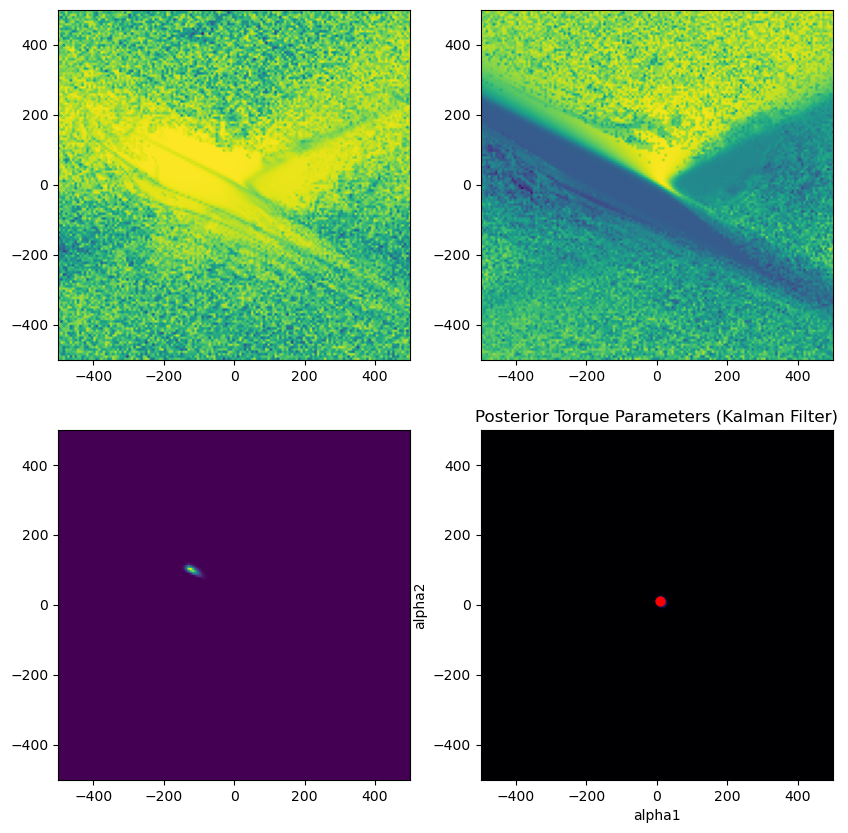

In [7]:
alpha1_min = -50 * ALPHA1
alpha1_max = 50 * ALPHA1
alpha2_min = -50 * ALPHA2
alpha2_max = 50 * ALPHA2


resolution = 150

alpha1_grid = np.linspace(alpha1_min, alpha1_max, resolution)
alpha2_grid = np.linspace(alpha2_min, alpha2_max, resolution)

ALPHA1_GRID, ALPHA2_GRID = np.meshgrid(alpha1_grid, alpha2_grid)
shape_chunk = ALPHA1_GRID.shape
ALPHA1_GRID = ALPHA1_GRID.flatten()
ALPHA2_GRID = ALPHA2_GRID.flatten()

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

params = np.stack((ALPHA1_GRID, ALPHA2_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][0].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][0].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman5.png', dpi=300)

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=100
                                   )
logl = logl.reshape(shape_chunk)

particle_P_gamma = 10
cmap = 'viridis' if particle_P_gamma == 1 else 'magma'
P = np.exp((logl - np.max(logl))/particle_P_gamma)
P /= np.sum(P)
P = gaussian_filter(P, 1)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

ax[0][1].imshow(logl, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto')
ax[1][1].imshow(P, extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max), origin='lower', aspect='auto', cmap=cmap)
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
ax[1][1].plot(ALPHA1, ALPHA2, 'ro', label='Ground Truth')
plt.xlabel('alpha1')
plt.ylabel('alpha2')
plt.savefig('particle5.png', dpi=300)
plt.show()